## Basic 2 Stage Model 
 
#### Stage 1: Macroeconomic forecast of market-wide rent

This notebook constructs a basic two-stage housing-rent model. Stage 1 forecasts the monthly market-wide mean rent using only information available from macroeconomic indicators. Stage 2 can later use this forecast as a market-condition feature for an individual-property model.

In the first stage, the target is aggregated to monthly mean rent because the macroeconomic features are monthly and are shared by all properties. A chronological split is used to avoid future information leaking into training.

## 1. Load and align the data

We join the rental observations and macroeconomic data by calendar month. Housing price and private-rent indexes are deliberately excluded from the predictors because this stage is intended to measure the predictive contribution of broader macroeconomic conditions.

In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from lightgbm import LGBMRegressor
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance

import os, sys
from pathlib import Path
_here = Path(os.environ.get('RENT_PROJECT_ROOT') or Path.cwd()).resolve()
sys.path.insert(0, str(next(p for p in [_here, *_here.parents] if (p / 'data' / 'config.py').exists())))      # final_report: data/config.py holds every path
from data import config as cfg
ROOT = cfg.ROOT
rent_path = cfg.TRAIN_CSV
macro_path = cfg.MACRO_FEATURES_CSV
access_path = cfg.HDB_ACCESSIBILITY_CSV
rent = pd.read_csv(rent_path)
macro = pd.read_csv(macro_path, parse_dates=['RENT_APPROVAL_DATE'])
rent['MONTH'] = pd.to_datetime(rent['RENT_APPROVAL_DATE']).dt.to_period('M').dt.to_timestamp()
rent['MONTHLY_RENT'] = pd.to_numeric(rent['MONTHLY_RENT'], errors='coerce')
monthly_rent = (rent.dropna(subset=['MONTH', 'MONTHLY_RENT'])
                .groupby('MONTH')['MONTHLY_RENT'].mean()
                .rename('mean_monthly_rent').reset_index())
macro = macro.rename(columns={'RENT_APPROVAL_DATE': 'MONTH'})
macro['MONTH'] = macro['MONTH'].dt.to_period('M').dt.to_timestamp()
macro_cols = [
    'MACRO_CPI_EX_ACCOM_YOY', 'MACRO_SORA_3M_PCT',
    'MACRO_REAL_GDP_YOY', 'MACRO_UNEMPLOYMENT_SA_PCT'
]
data = monthly_rent.merge(macro[['MONTH'] + macro_cols], on='MONTH', how='inner').sort_values('MONTH')
data['rent_yoy_pct'] = data['mean_monthly_rent'].pct_change(12) * 100
print(f'Observations: {len(data):,}')
display(data.head())


Observations: 51


,MONTH,mean_monthly_rent,MACRO_CPI_EX_ACCOM_YOY,MACRO_SORA_3M_PCT,MACRO_REAL_GDP_YOY,MACRO_UNEMPLOYMENT_SA_PCT,rent_yoy_pct
0,2021-01-01,2048.901246,-0.242931,0.1661,-3.9,3.4,NaN
1,2021-02-01,2048.546642,-0.029132,0.1694,-3.9,3.4,NaN
2,2021-03-01,2068.319028,0.179341,0.1996,-0.1,3.2,NaN
3,2021-04-01,2081.961679,0.820046,0.2216,-0.1,3.2,NaN
4,2021-05-01,2105.434286,1.532648,0.1862,-0.1,3.2,NaN


## 2. Explore the target and macroeconomic trends

The level of mean rent usually trends over time, so a model can appear accurate simply by learning the trend. The YoY target is also inspected because it is a more stationary measure of market growth.

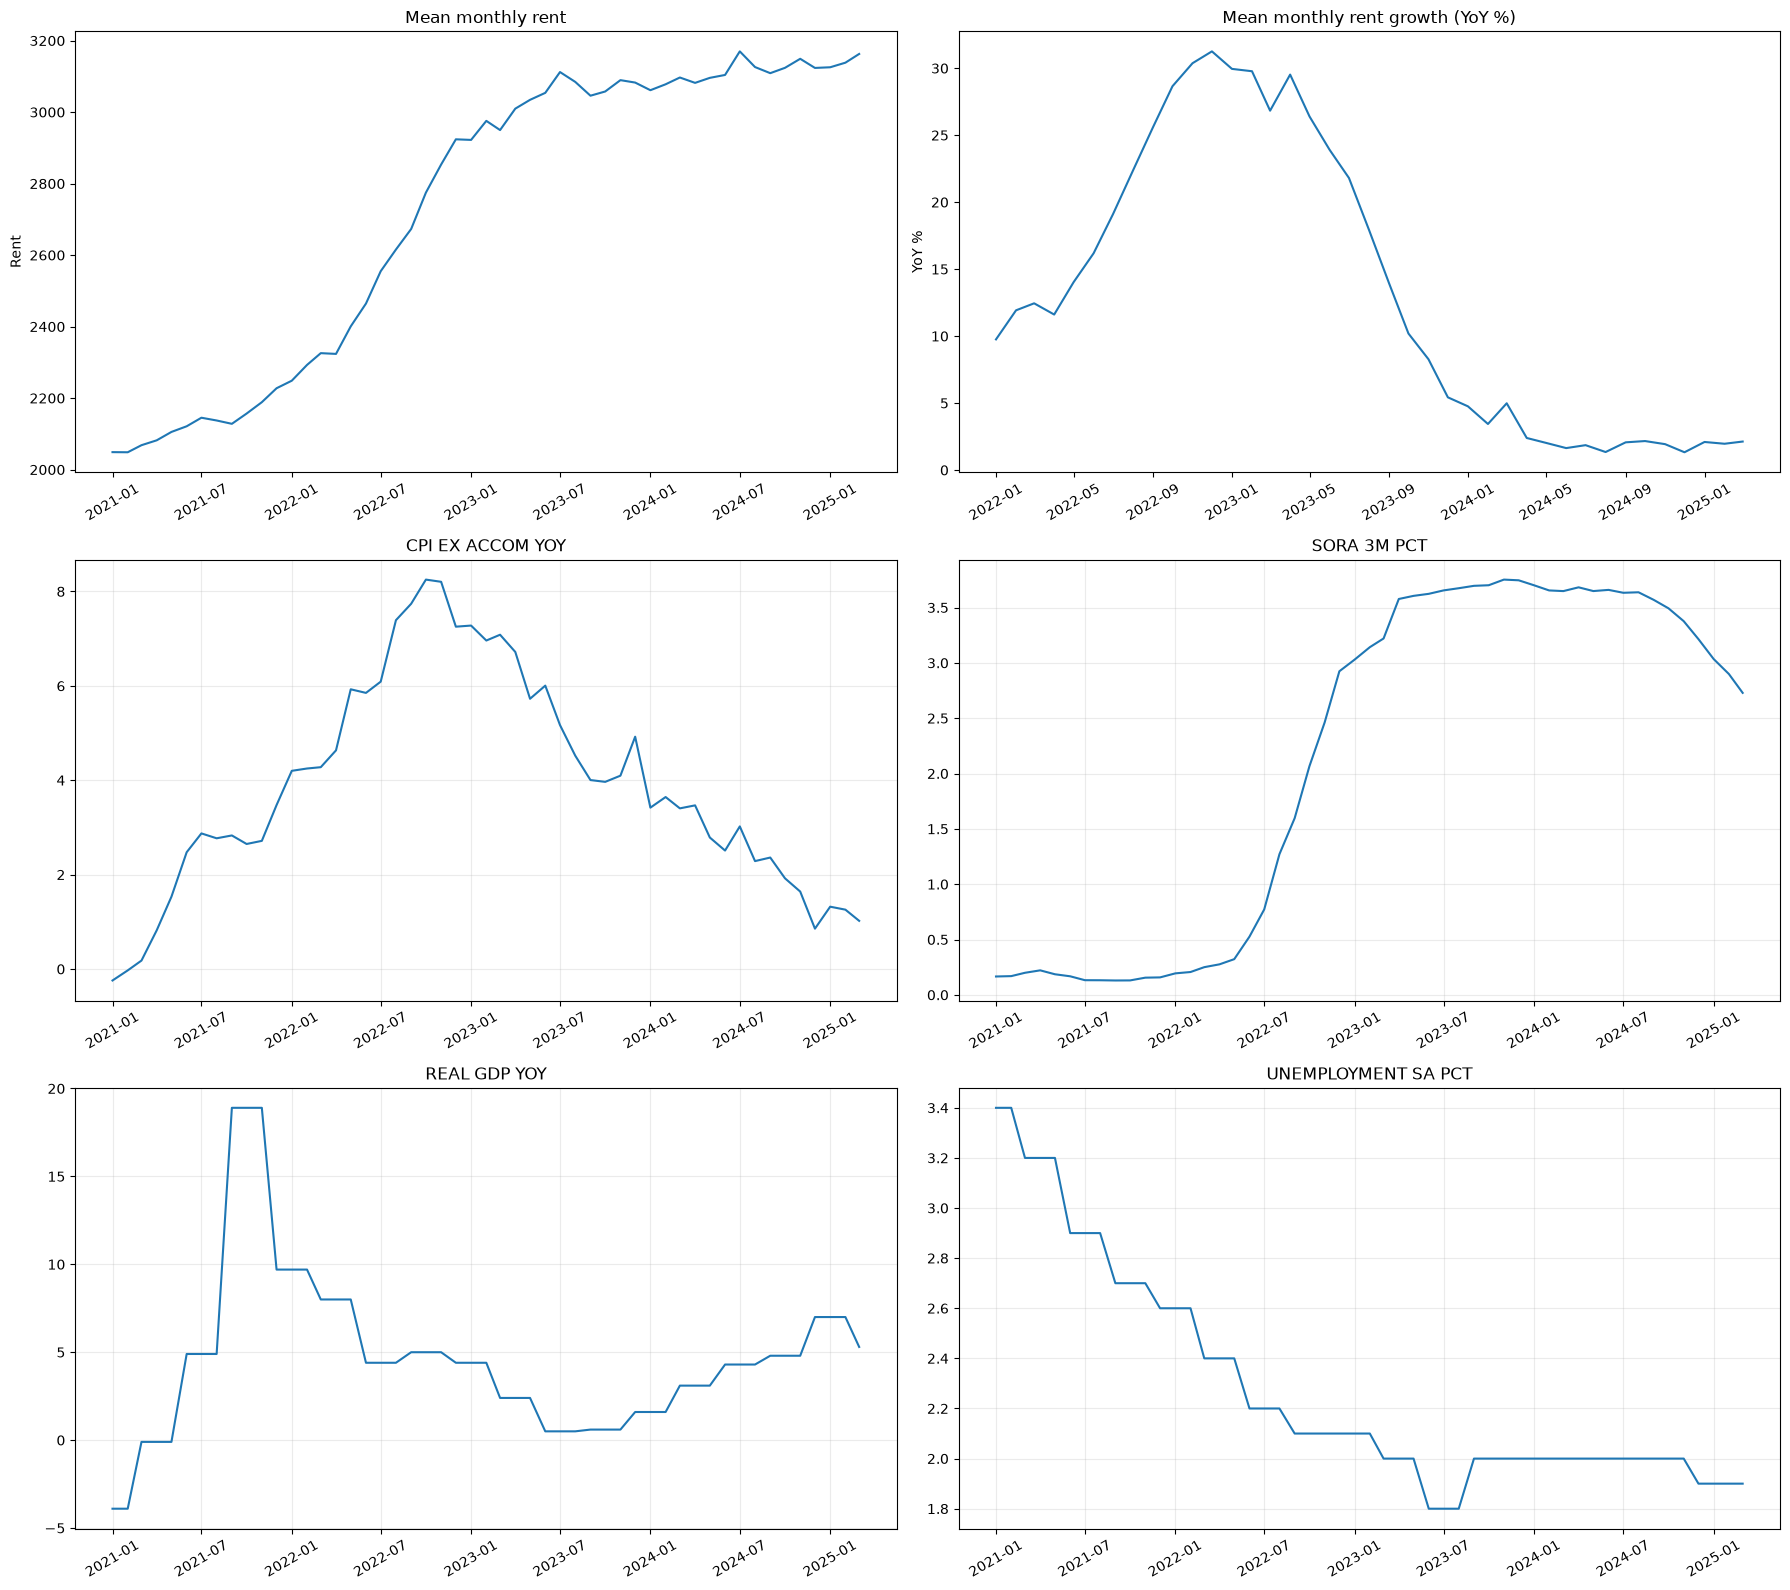

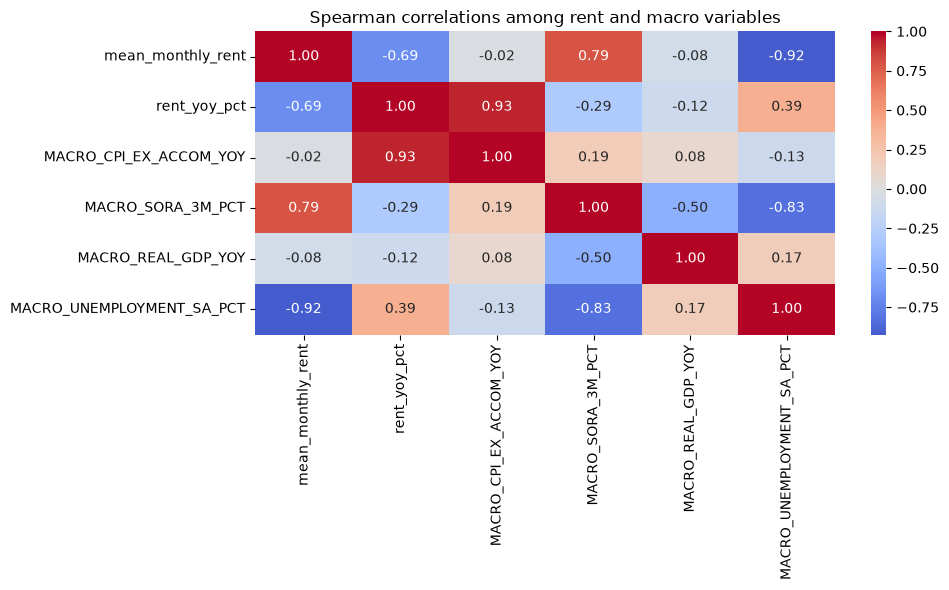

In [45]:
fig, axes = plt.subplots(3, 2, figsize=(18, 16))
axes[0, 0].plot(data['MONTH'], data['mean_monthly_rent'])
axes[0, 0].set_title('Mean monthly rent')
axes[0, 0].set_ylabel('Rent')
axes[0, 1].plot(data['MONTH'], data['rent_yoy_pct'])
axes[0, 1].set_title('Mean monthly rent growth (YoY %)')
axes[0, 1].set_ylabel('YoY %')
for ax, col in zip(axes.flat[2:], macro_cols):
    ax.plot(data['MONTH'], data[col])
    ax.set_title(col.replace('MACRO_', '').replace('_', ' '))
    ax.grid(alpha=0.25)
for ax in axes.flat:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

corr = data[['mean_monthly_rent', 'rent_yoy_pct'] + macro_cols].corr(method='spearman')
plt.figure(figsize=(10, 6))
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Spearman correlations among rent and macro variables')
plt.tight_layout(); plt.show()


## 3. Create lagged predictors and chronological splits

Only lagged macro variables are used, ensuring that the model does not use the current month’s information when forecasting that month. The evaluation uses training through February 2024 and validation from March 2024 through April 2025; no test set is used for reported metrics.

In [46]:
model_data = data.copy()
feature_cols = []
for col in macro_cols:
    for lag in (1, 3, 6, 12):
        name = f'{col}_lag{lag}'
        model_data[name] = model_data[col].shift(lag)
        feature_cols.append(name)
model_data = model_data.dropna(subset=feature_cols + ['mean_monthly_rent']).copy()

# Shared chronological windows for Stage 1 and Stage 2.
# Chronological windows for data available from Jan 2021 through Mar 2025.
# The 12-month lag construction means usable model rows begin in Jan 2022.
# Two-way evaluation only: fit through Feb 2024 and validate from Mar 2024
# through Apr 2025. Test rows are reserved only for competition submission.
FIT_END = pd.Timestamp('2024-03-01')
VALID_START = pd.Timestamp('2024-04-01')
VALID_END = pd.Timestamp('2025-03-01')
TEST_START = pd.Timestamp('2099-01-01')
TEST_END = pd.Timestamp('2099-12-01')
train = model_data[model_data['MONTH'] <= FIT_END]
valid = model_data[model_data['MONTH'].between(VALID_START, VALID_END)]
test = model_data[model_data['MONTH'].between(TEST_START, TEST_END)].copy()
X_train, y_train = train[feature_cols], train['mean_monthly_rent']
X_valid, y_valid = valid[feature_cols], valid['mean_monthly_rent']
print({name: len(frame) for name, frame in [('train', train), ('validation', valid)]})
print('Validation month range:', valid['MONTH'].min(), 'to', valid['MONTH'].max(), '| unique months:', valid['MONTH'].nunique())
# No observed test split is used for evaluation.


{'train': 24, 'validation': 12}
Validation month range: 2024-01-01 00:00:00 to 2024-12-01 00:00:00 | unique months: 12


## 4. Fit models and compare against baselines

LightGBM and Random Forest are retained as deliberately transparent machine-learning comparisons. A damped Holt exponential-smoothing model is then added as the preferred time-series alternative. The baselines are a previous-month forecast and a seasonal-naive forecast using the value from 12 months earlier.

The monthly series contains only a few dozen usable observations after constructing 12-month lags. This is too little data for high-capacity tree ensembles to learn stable nonlinear relationships: they can fit the training period while extrapolating poorly over the short holdout. Holt smoothing instead estimates only the current level and trend, applies exponentially decreasing weights to older observations, and damps the trend so that it does not grow unrealistically far beyond the observed range. This gives a parsimonious forecast that is aligned with the temporal structure of the target and does not require dozens of macro-feature coefficients.

In [47]:
lgbm_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', LGBMRegressor(n_estimators=500, learning_rate=0.03, num_leaves=15,
                           subsample=0.8, colsample_bytree=0.8,
                           objective='regression', random_state=42, verbosity=-1))
])
# With only a few dozen monthly observations, Holt is the preferred final
# forecast, while the ML models are retained to document their performance.
stage1_model = ExponentialSmoothing(
    train['mean_monthly_rent'].to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
forest = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('model', RandomForestRegressor(n_estimators=500, min_samples_leaf=2, random_state=42))
])
lgbm_model.fit(X_train, y_train)
predictions = {'LightGBM': lgbm_model.predict(X_valid),
              'Holt damped trend': stage1_model.forecast(len(valid))}
forest.fit(X_train, y_train)
predictions['Random Forest'] = forest.predict(X_valid)
validation_predictions = {'LightGBM': lgbm_model.predict(X_valid),
                         'Holt damped trend': stage1_model.forecast(len(valid)),
                         'Random Forest': forest.predict(X_valid)}

validation_indexed = model_data.set_index('MONTH')
validation_months = valid['MONTH']
predictions['Previous month'] = validation_months.map(validation_indexed['mean_monthly_rent'].shift(1)).to_numpy()
predictions['Same month previous year'] = validation_months.map(validation_indexed['mean_monthly_rent'].shift(12)).to_numpy()

def metrics(y_true, y_pred):
    mask = np.isfinite(y_true) & np.isfinite(y_pred)
    n = int(mask.sum())
    if n == 0:
        return {'N': 0, 'MAE': np.nan, 'RMSE': np.nan, 'R2': np.nan}
    return {'N': n, 'MAE': mean_absolute_error(y_true[mask], y_pred[mask]),
            'RMSE': mean_squared_error(y_true[mask], y_pred[mask]) ** 0.5,
            'R2': r2_score(y_true[mask], y_pred[mask]) if n >= 2 else np.nan}

evaluation = pd.DataFrame({name: metrics(y_valid.to_numpy(), pred) for name, pred in predictions.items()}).T
display(evaluation.sort_values('MAE'))


,N,MAE,RMSE,R2
Previous month,12.0,23.896276,28.370707,0.068623
Holt damped trend,12.0,66.613750,72.447462,-5.073397
Same month previous year,12.0,75.099738,82.440191,-6.864359
Random Forest,12.0,127.815278,143.825579,-22.936332
LightGBM,12.0,323.670102,325.002362,-121.224528


### Holt exponential-smoothing forecast

The final Stage 1 forecast uses a damped Holt trend. It estimates a level and a trend from the short monthly rent series, exponentially downweights older observations, and dampens the trend for stable extrapolation.

,N,MAE,RMSE,R2
Validation,12.0,66.61375,72.447462,-5.073397


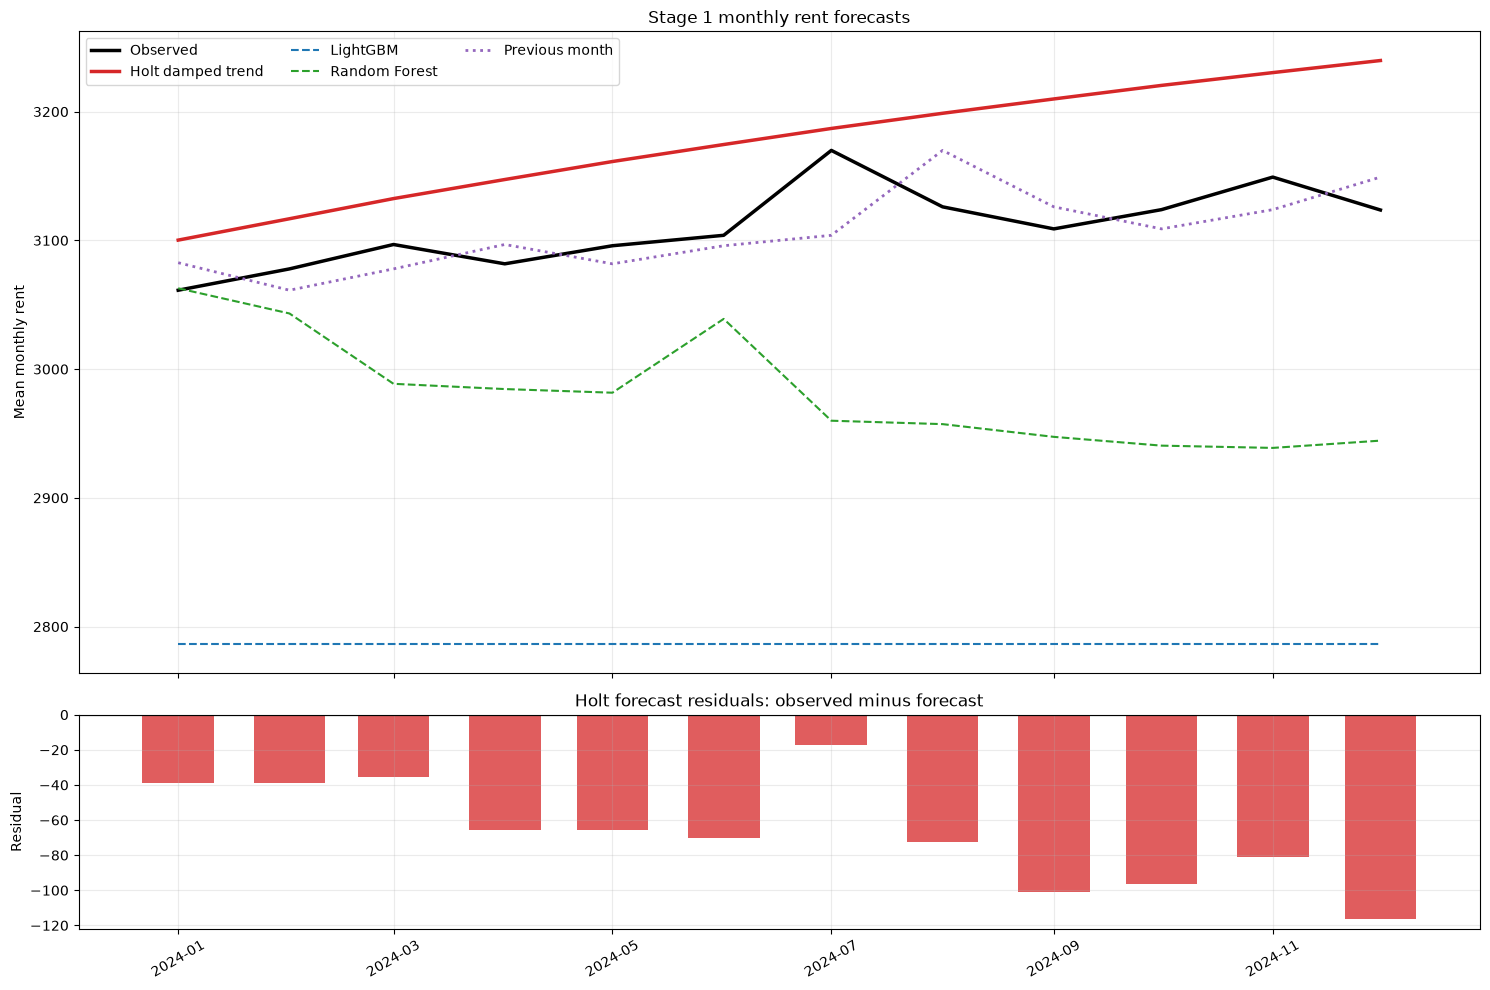

In [48]:
# Explicit Holt evaluation with chronological refits.
holt_fit_model = ExponentialSmoothing(
    train['mean_monthly_rent'].to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
holt_valid_prediction = holt_fit_model.forecast(len(valid))
holt_fit_valid_model = ExponentialSmoothing(
    pd.concat([train['mean_monthly_rent'], valid['mean_monthly_rent']]).to_numpy(dtype=float),
    trend='add', damped_trend=True, initialization_method='estimated'
).fit(optimized=True)
holt_evaluation = pd.DataFrame({
    'Validation': metrics(y_valid.to_numpy(), holt_valid_prediction),
}).T
display(holt_evaluation)

# Holt is the Stage 1 forecast passed to Stage 2. In-sample fitted values
# are used for fit months; validation and test months use genuine forecasts.
holt_by_month = pd.concat([
    pd.Series(holt_fit_model.fittedvalues, index=train['MONTH']),
    pd.Series(holt_valid_prediction, index=valid['MONTH']),
]).groupby(level=0).last()
stage1_monthly = model_data[['MONTH']].copy()
stage1_monthly['stage1_forecast'] = stage1_monthly['MONTH'].map(holt_by_month)

# Clear Stage 1 forecast chart.
chart = pd.DataFrame({'MONTH': valid['MONTH'], 'Observed': y_valid.to_numpy(),
                      'Holt damped trend': holt_valid_prediction,
                      'LightGBM': predictions['LightGBM'],
                      'Random Forest': predictions['Random Forest'],
                      'Previous month': predictions['Previous month']})
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 10), sharex=True,
                              gridspec_kw={'height_ratios': [3, 1]})
ax1.plot(chart['MONTH'], chart['Observed'], color='black', linewidth=2.5, label='Observed')
ax1.plot(chart['MONTH'], chart['Holt damped trend'], color='#d62728', linewidth=2.5, label='Holt damped trend')
ax1.plot(chart['MONTH'], chart['LightGBM'], color='#1f77b4', linestyle='--', label='LightGBM')
ax1.plot(chart['MONTH'], chart['Random Forest'], color='#2ca02c', linestyle='--', label='Random Forest')
ax1.plot(chart['MONTH'], chart['Previous month'], color='#9467bd', linestyle=':', linewidth=2, label='Previous month')
ax1.set_title('Stage 1 monthly rent forecasts')
ax1.set_ylabel('Mean monthly rent')
ax1.legend(ncol=3, frameon=True)
ax1.grid(alpha=.25)
ax2.axhline(0, color='black', linewidth=.8)
ax2.bar(chart['MONTH'], chart['Observed'] - chart['Holt damped trend'], width=20, color='#d62728', alpha=.75)
ax2.set_title('Holt forecast residuals: observed minus forecast')
ax2.set_ylabel('Residual')
ax2.grid(alpha=.25)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()


## 5. Evaluate forecasts visually

The validation period is plotted against the observed monthly mean rent. A useful model should track turning points and should outperform both simple baselines, especially the seasonal-naive forecast.

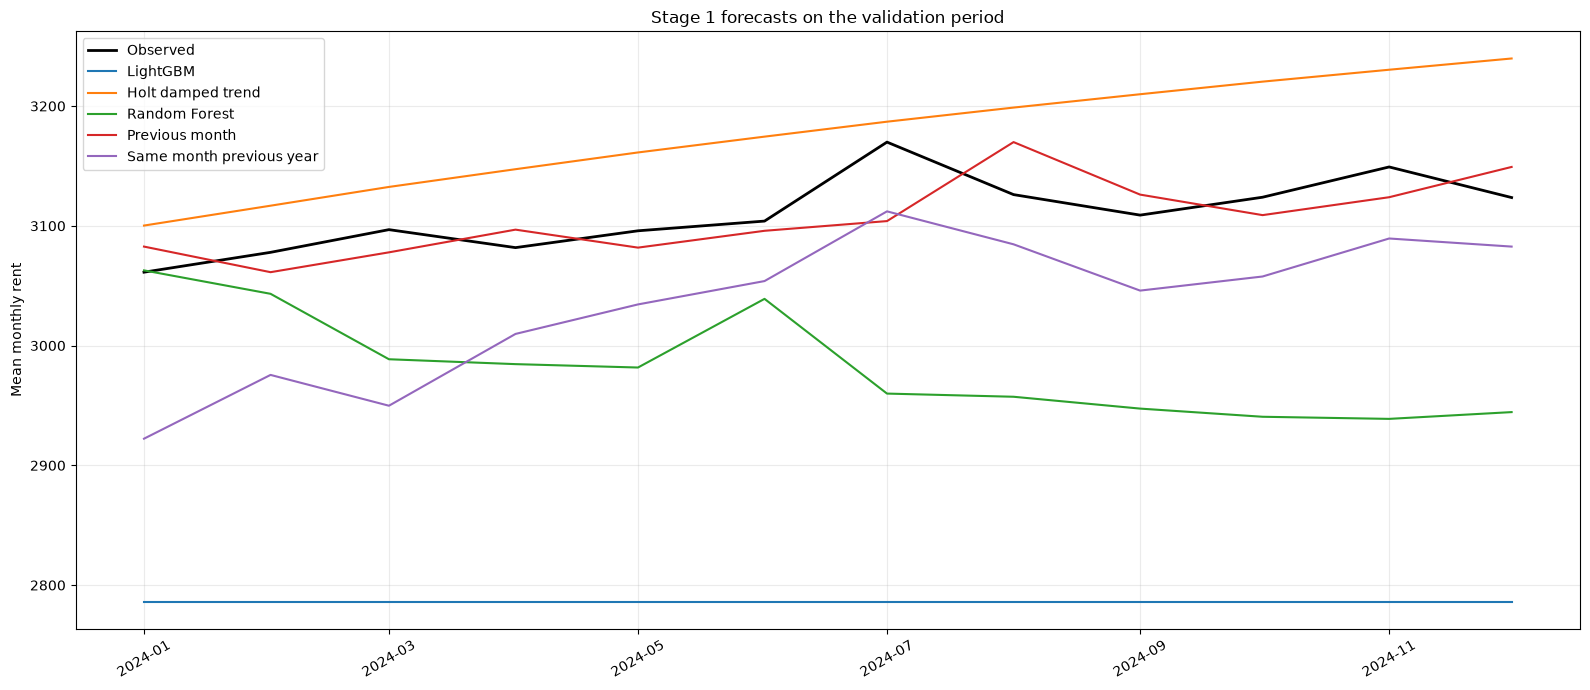

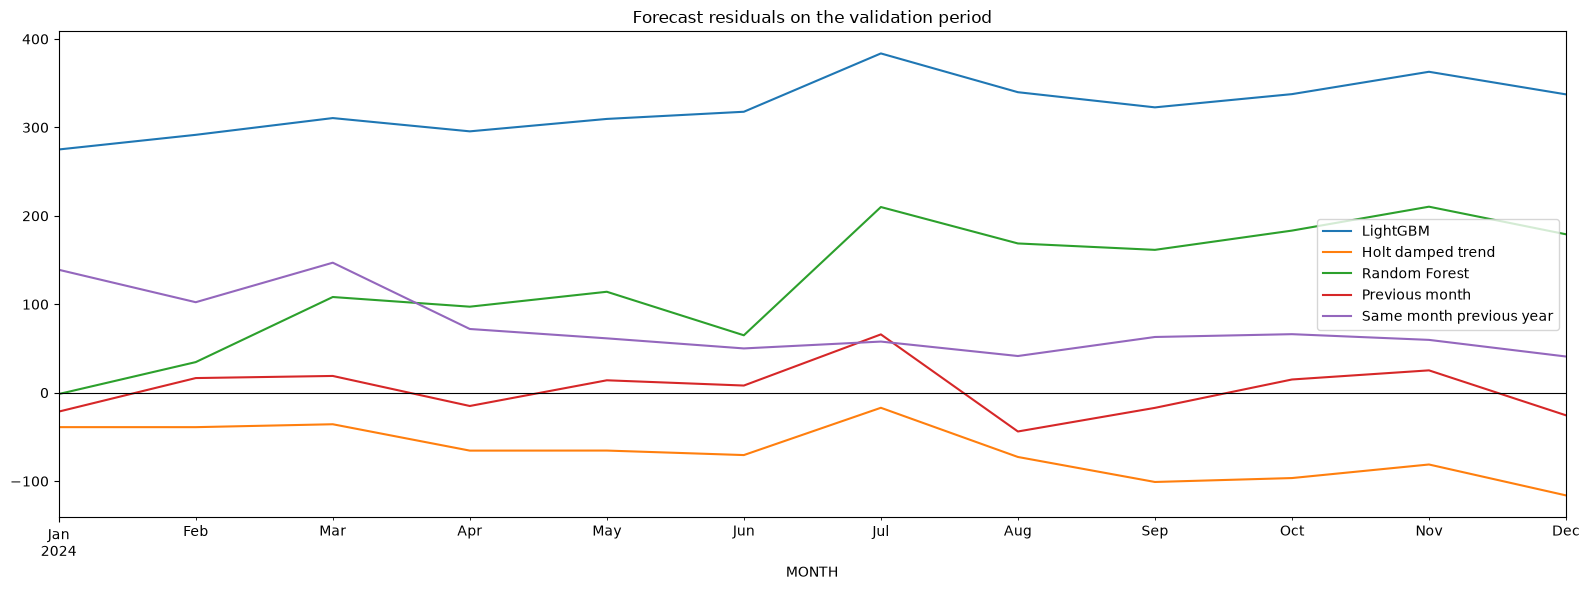

In [49]:
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(valid['MONTH'], y_valid, color='black', linewidth=2, label='Observed')
for name, pred in predictions.items():
    ax.plot(valid['MONTH'], pred, linewidth=1.5, label=name)
ax.set_title('Stage 1 forecasts on the validation period')
ax.set_ylabel('Mean monthly rent')
ax.legend()
ax.grid(alpha=0.25)
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

residuals = pd.DataFrame({'MONTH': valid['MONTH'], **{name: y_valid.to_numpy() - pred for name, pred in predictions.items()}})
residuals.set_index('MONTH').plot(figsize=(16, 6), title='Forecast residuals on the validation period')
plt.axhline(0, color='black', linewidth=0.8); plt.tight_layout(); plt.show()


## 6. Interpretation and hand-off to Stage 2

The preferred Stage 1 model is selected using validation performance. The current evaluation uses training observations through February 2024 and validation observations from March 2024 through April 2025; no test set contributes to the reported metrics. The resulting monthly forecast is joined back to individual property records by month and supplied to Stage 2 as a market-level feature.

Because the dataset contains only a small number of monthly observations, complex models should be treated cautiously. If the macro models do not beat the seasonal-naive baseline, macroeconomic variables may add limited short-horizon forecasting value; Stage 2 should still evaluate whether the forecast improves individual-property predictions.

# Stage 2 — Property-level residual modelling

Two separate pipelines are evaluated: (1) Holt Stage 1 → XGBoost Stage 2 and (2) Random Forest Stage 1 → XGBoost Stage 2. Each Stage 2 model predicts the residual `observed rent - its own Stage 1 forecast`; the final prediction is the corresponding Stage 1 forecast plus the predicted residual.

The Stage 2 models use property-level variables, one-hot encoded categorical attributes, and accessibility features from `hdb_features_with_accessibility.csv`, including MRT, bus-stop, school, and travel-time measures. Mutual-information selection retains a consistent numeric feature matrix before XGBoost models the nonlinear residual effects.

In [50]:
from xgboost import XGBRegressor
from sklearn.feature_selection import SelectKBest, mutual_info_regression
from sklearn.model_selection import ParameterGrid
TARGET = 'MONTHLY_RENT'
TRAIN_PARQUET = cfg.TRAIN_FEATURES_PARQUET
TEST_PARQUET = cfg.TEST_FEATURES_PARQUET
if not TRAIN_PARQUET.exists() or not TEST_PARQUET.exists():
    raise FileNotFoundError('Expected data/train_features.parquet and data/test_features.parquet.')
property_df = pd.read_parquet(TRAIN_PARQUET, engine='pyarrow')
property_date = 'RENT_APPROVAL_DATE' if 'RENT_APPROVAL_DATE' in property_df else 'approval_date'
property_df[property_date] = pd.to_datetime(property_df[property_date])
property_df['MONTH'] = property_df[property_date].dt.to_period('M').dt.to_timestamp()

# Stage 1: only the four original macro variables and their lagged versions.
# stage1_monthly contains the Holt Stage 1 forecast. Add a parallel
# Random Forest Stage 1 forecast for the second residual pipeline.
stage1_monthly['stage1_rf_forecast'] = forest.predict(model_data[feature_cols])
property_df = property_df.merge(stage1_monthly, on='MONTH', how='inner')

# Stage 2 accessibility enrichment from the requested source file.
access = pd.read_csv(access_path)
access_cols = ['ADDRESS_KEY', 'MRT_DISTANCE_KM', 'BUS_STOP_DISTANCE_KM', 'MRT_WITHIN_250M', 'BUS_STOPS_WITHIN_250M', 'MRT_WITHIN_750M', 'BUS_STOPS_WITHIN_750M', 'SCHOOL_DISTANCE_KM', 'mean_travel_time_min', 'median_travel_time_min', 'cbd_travel_time_min', 'regional_hub_travel_time_min', 'essential_services_time_min', 'education_access_time_min', 'ACCESSIBILITY_SCORE']
access = access[[c for c in access_cols if c in access.columns]].drop_duplicates('ADDRESS_KEY')
property_df = property_df.merge(access, on='ADDRESS_KEY', how='left', validate='many_to_one')
property_df['stage1_residual'] = property_df[TARGET] - property_df['stage1_forecast']

fit_mask = property_df['MONTH'] <= FIT_END
valid_mask = property_df['MONTH'].between(VALID_START, VALID_END)
# No test mask: all reported Stage 2 metrics use valid_mask only.
property_df['stage1_rf_residual'] = property_df[TARGET] - property_df['stage1_rf_forecast']
excluded = {TARGET, 'stage1_forecast', 'stage1_rf_forecast', 'stage1_residual', 'stage1_rf_residual', 'MONTH', property_date, 'ADDRESS_KEY'}
stage2_feature_cols = [c for c in property_df.columns if c not in excluded and not c.lower().startswith(('macro_', 'coe_', 'stock_')) and not pd.api.types.is_datetime64_any_dtype(property_df[c])]
X = pd.get_dummies(property_df[stage2_feature_cols], dummy_na=True)
X = X.replace([np.inf, -np.inf], np.nan).fillna(-999)
X_fit, X_valid = X.loc[fit_mask], X.loc[valid_mask]
y_fit = property_df.loc[fit_mask, 'stage1_residual']
y_valid = property_df.loc[valid_mask, 'stage1_residual']
print(f'Rows: fit={len(X_fit):,}, validation={len(X_valid):,}')
print(f'Candidate encoded Stage 2 features before selection: {X.shape[1]:,}')
print('Accessibility features added:', [c for c in access_cols if c in property_df.columns])


Rows: fit=68,218, validation=35,239
Candidate encoded Stage 2 features before selection: 12,971
Accessibility features added: ['ADDRESS_KEY', 'MRT_DISTANCE_KM', 'BUS_STOP_DISTANCE_KM', 'MRT_WITHIN_250M', 'BUS_STOPS_WITHIN_250M', 'MRT_WITHIN_750M', 'BUS_STOPS_WITHIN_750M', 'SCHOOL_DISTANCE_KM', 'mean_travel_time_min', 'median_travel_time_min', 'cbd_travel_time_min', 'regional_hub_travel_time_min', 'essential_services_time_min', 'education_access_time_min', 'ACCESSIBILITY_SCORE']


## Stage 2 training and evaluation

Both pipelines use the same chronological evaluation design: training observations through February 2024 and validation observations from March 2024 through April 2025. No test set is used for the reported metrics.

For the Holt pipeline, Stage 2 is trained on residuals from the Holt market-level forecast. For the Random Forest pipeline, Stage 2 is trained independently on residuals from the Random Forest market-level forecast. Each residual model uses the fit-period rows for training, selects hyperparameters using validation residuals, and is then refit on the combined fit and validation rows for the final validation-period comparison. The validation table reports MAE, RMSE, R², and the number of evaluated property rows.

In [51]:
# Feature selection happens before fitting XGBoost and is learned from 2023 only.
k = min(100, X_fit.shape[1])
selector = SelectKBest(mutual_info_regression, k=k)
X_fit_selected = selector.fit_transform(X_fit, y_fit)
X_valid_selected = selector.transform(X_valid)
selected_features = X.columns[selector.get_support()].tolist()
print(f'Selected {len(selected_features)} of {X.shape[1]} encoded features')

def make_xgb(params=None):
    base = dict(n_estimators=800, max_depth=6, learning_rate=.05,
                subsample=.8, colsample_bytree=.8, objective='reg:squarederror',
                eval_metric='mae', random_state=42, n_jobs=-1)
    if params: base.update(params)
    return XGBRegressor(**base)

baseline_model = make_xgb()
baseline_model.fit(X_fit_selected, y_fit, eval_set=[(X_valid_selected, y_valid)], verbose=False)
baseline_valid_residual = baseline_model.predict(X_valid_selected)

tuning_grid = list(ParameterGrid({'max_depth': [3, 6], 'learning_rate': [.03, .07], 'min_child_weight': [1, 5]}))
tuning_rows = []
for params in tuning_grid:
    candidate = make_xgb(params)
    candidate.fit(X_fit_selected, y_fit, eval_set=[(X_valid_selected, y_valid)], verbose=False)
    pred = candidate.predict(X_valid_selected)
    tuning_rows.append({'params': params, 'MAE': mean_absolute_error(y_valid, pred), 'RMSE': mean_squared_error(y_valid, pred) ** .5})
tuning_results = pd.DataFrame(tuning_rows).sort_values('MAE')
display(tuning_results)
best_params = tuning_results.iloc[0]['params']
residual_model = make_xgb(best_params)
X_fit_valid = np.vstack([X_fit_selected, X_valid_selected])
y_fit_valid = pd.concat([y_fit, y_valid])
residual_model.fit(X_fit_valid, y_fit_valid, verbose=False)

def score(y_true, prediction):
    y_true = np.asarray(y_true, dtype=float).reshape(-1)
    prediction = np.asarray(prediction, dtype=float).reshape(-1)
    mask = np.isfinite(y_true) & np.isfinite(prediction)
    n = int(mask.sum())
    if n == 0:
        return {'N': 0, 'MAE': np.nan, 'RMSE': np.nan, 'R2': np.nan}
    return {'N': n,
            'MAE': float(mean_absolute_error(y_true[mask], prediction[mask])),
            'RMSE': float(mean_squared_error(y_true[mask], prediction[mask]) ** .5),
            'R2': float(r2_score(y_true[mask], prediction[mask])) if n >= 2 else np.nan}

def evaluate(mask, X_part):
    stage1 = property_df.loc[mask, 'stage1_forecast'].to_numpy()
    actual = property_df.loc[mask, TARGET].to_numpy()
    corrected = stage1 + residual_model.predict(X_part)
    return score(actual, stage1), score(actual, corrected), actual, stage1, corrected

valid_stage1, valid_stage2, valid_actual, valid_base, valid_corrected = evaluate(valid_mask, X_valid_selected)
# Preserve the Holt Stage 2 metrics; the submission cell uses a different
# variable for encoded test features.
evaluation = pd.DataFrame({'Stage 1 validation': valid_stage1, 'Stage 2 validation': valid_stage2}).T
display(evaluation)


Selected 100 of 12971 encoded features


,params,MAE,RMSE
1,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",415.463223,562.181407
0,"{'learning_rate': 0.03, 'max_depth': 3, 'min_c...",415.680100,562.289051
4,"{'learning_rate': 0.07, 'max_depth': 3, 'min_c...",417.647730,565.140121
5,"{'learning_rate': 0.07, 'max_depth': 3, 'min_c...",420.957559,567.751868
2,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",424.660038,570.149982
3,"{'learning_rate': 0.03, 'max_depth': 6, 'min_c...",427.475445,573.338237
6,"{'learning_rate': 0.07, 'max_depth': 6, 'min_c...",436.664286,580.881206
7,"{'learning_rate': 0.07, 'max_depth': 6, 'min_c...",440.540129,585.459549


,N,MAE,RMSE,R2
Stage 1 validation,35239.0,516.387802,672.351728,-0.009368
Stage 2 validation,35239.0,358.343518,484.430551,0.476014


## Stage 2 comparison: Random Forest Stage 1 residuals

This is an independent comparison pipeline. Random Forest first forecasts the market-level monthly rent, after which a separate XGBoost model learns `observed rent - Random Forest forecast` using the same property and accessibility features. Its validation metrics are reported beside the Holt Stage 1 → XGBoost Stage 2 pipeline so that the contribution of the Stage 1 choice can be compared directly.

In [38]:
# Select residual features independently for the Random Forest Stage 1 pipeline.
y_fit_rf = property_df.loc[fit_mask, 'stage1_rf_residual']
y_valid_rf = property_df.loc[valid_mask, 'stage1_rf_residual']
selector_rf = SelectKBest(mutual_info_regression, k=min(100, X_fit.shape[1]))
X_fit_rf = selector_rf.fit_transform(X_fit, y_fit_rf)
X_valid_rf = selector_rf.transform(X_valid)

rf_residual_tuning = []
for params in tuning_grid:
    candidate = make_xgb(params)
    candidate.fit(X_fit_rf, y_fit_rf, eval_set=[(X_valid_rf, y_valid_rf)], verbose=False)
    pred = candidate.predict(X_valid_rf)
    rf_residual_tuning.append({'params': params, 'MAE': mean_absolute_error(y_valid_rf, pred), 'RMSE': mean_squared_error(y_valid_rf, pred) ** .5})
rf_best_params = pd.DataFrame(rf_residual_tuning).sort_values('MAE').iloc[0]['params']
rf_residual_model = make_xgb(rf_best_params)
rf_residual_model.fit(np.vstack([X_fit_rf, X_valid_rf]), pd.concat([y_fit_rf, y_valid_rf]), verbose=False)

rf_stage1_valid = property_df.loc[valid_mask, 'stage1_rf_forecast'].to_numpy()
rf_stage2_valid_pred = rf_stage1_valid + rf_residual_model.predict(X_valid_rf)
rf_pipeline_evaluation = pd.DataFrame({
    'RF Stage 1 validation': score(property_df.loc[valid_mask, TARGET], rf_stage1_valid),
    'RF Stage 2 validation': score(property_df.loc[valid_mask, TARGET], rf_stage2_valid_pred),
    # Test predictions are retained for optional submission only.
}).T
display(rf_pipeline_evaluation)

def comparison_row(label, result):
    result = dict(result)
    return {'Pipeline': label, 'N': int(result.get('N', 0)),
            'MAE': float(result['MAE']), 'RMSE': float(result['RMSE']),
            'R2': float(result['R2']) if pd.notna(result.get('R2')) else np.nan}

pipeline_comparison = pd.DataFrame([
    comparison_row('Holt Stage 1 → XGBoost Stage 2 validation', valid_stage2),
    comparison_row('Random Forest Stage 1 → XGBoost Stage 2 validation', rf_pipeline_evaluation.loc['RF Stage 2 validation']),
]).set_index('Pipeline')
display(pipeline_comparison)

,N,MAE,RMSE,R2
RF Stage 1 validation,38342.0,524.290189,681.503277,-0.058840
RF Stage 2 validation,38342.0,344.407877,470.499310,0.495324


,N,MAE,RMSE,R2
Pipeline,,,,
Holt Stage 1 → XGBoost Stage 2 validation,38342,322.909000,439.005333,0.560626
Random Forest Stage 1 → XGBoost Stage 2 validation,38342,344.407877,470.499310,0.495324


In [18]:
# Consolidated validation metrics for all model combinations.
# This cell only formats existing results; it does not retrain models.
model_combination_metrics = pd.DataFrame([
    comparison_row('Holt Stage 1', evaluation.loc['Stage 1 validation']),
    comparison_row('Holt Stage 1 + XGBoost residual', evaluation.loc['Stage 2 validation']),
    comparison_row('Random Forest Stage 1', rf_pipeline_evaluation.loc['RF Stage 1 validation']),
    comparison_row('Random Forest Stage 1 + XGBoost residual', rf_pipeline_evaluation.loc['RF Stage 2 validation']),
]).sort_values('RMSE').reset_index(drop=True)
print('Validation metrics for model combinations:')
display(model_combination_metrics.style.format({'MAE': '{:,.2f}', 'RMSE': '{:,.2f}', 'R2': '{:.4f}'}))

Validation metrics for model combinations:


,Pipeline,N,MAE,RMSE,R2
0,Holt Stage 1 + XGBoost residual,35158,318.36,434.67,0.5652
1,Random Forest Stage 1 + XGBoost residual,35158,339.49,465.95,0.5004
2,Holt Stage 1,35158,504.30,660.42,-0.0037
3,Random Forest Stage 1,35158,511.16,668.86,-0.0295


## Stage 2 diagnostics and feature importance

The validation diagnostics compare the market-only Stage 1 forecast with the corrected Stage 2 forecast. Feature importance identifies which property and accessibility variables help explain deviations from market-wide conditions. These importances are associative rather than causal, and all conclusions are limited to the March 2024–April 2025 validation window.

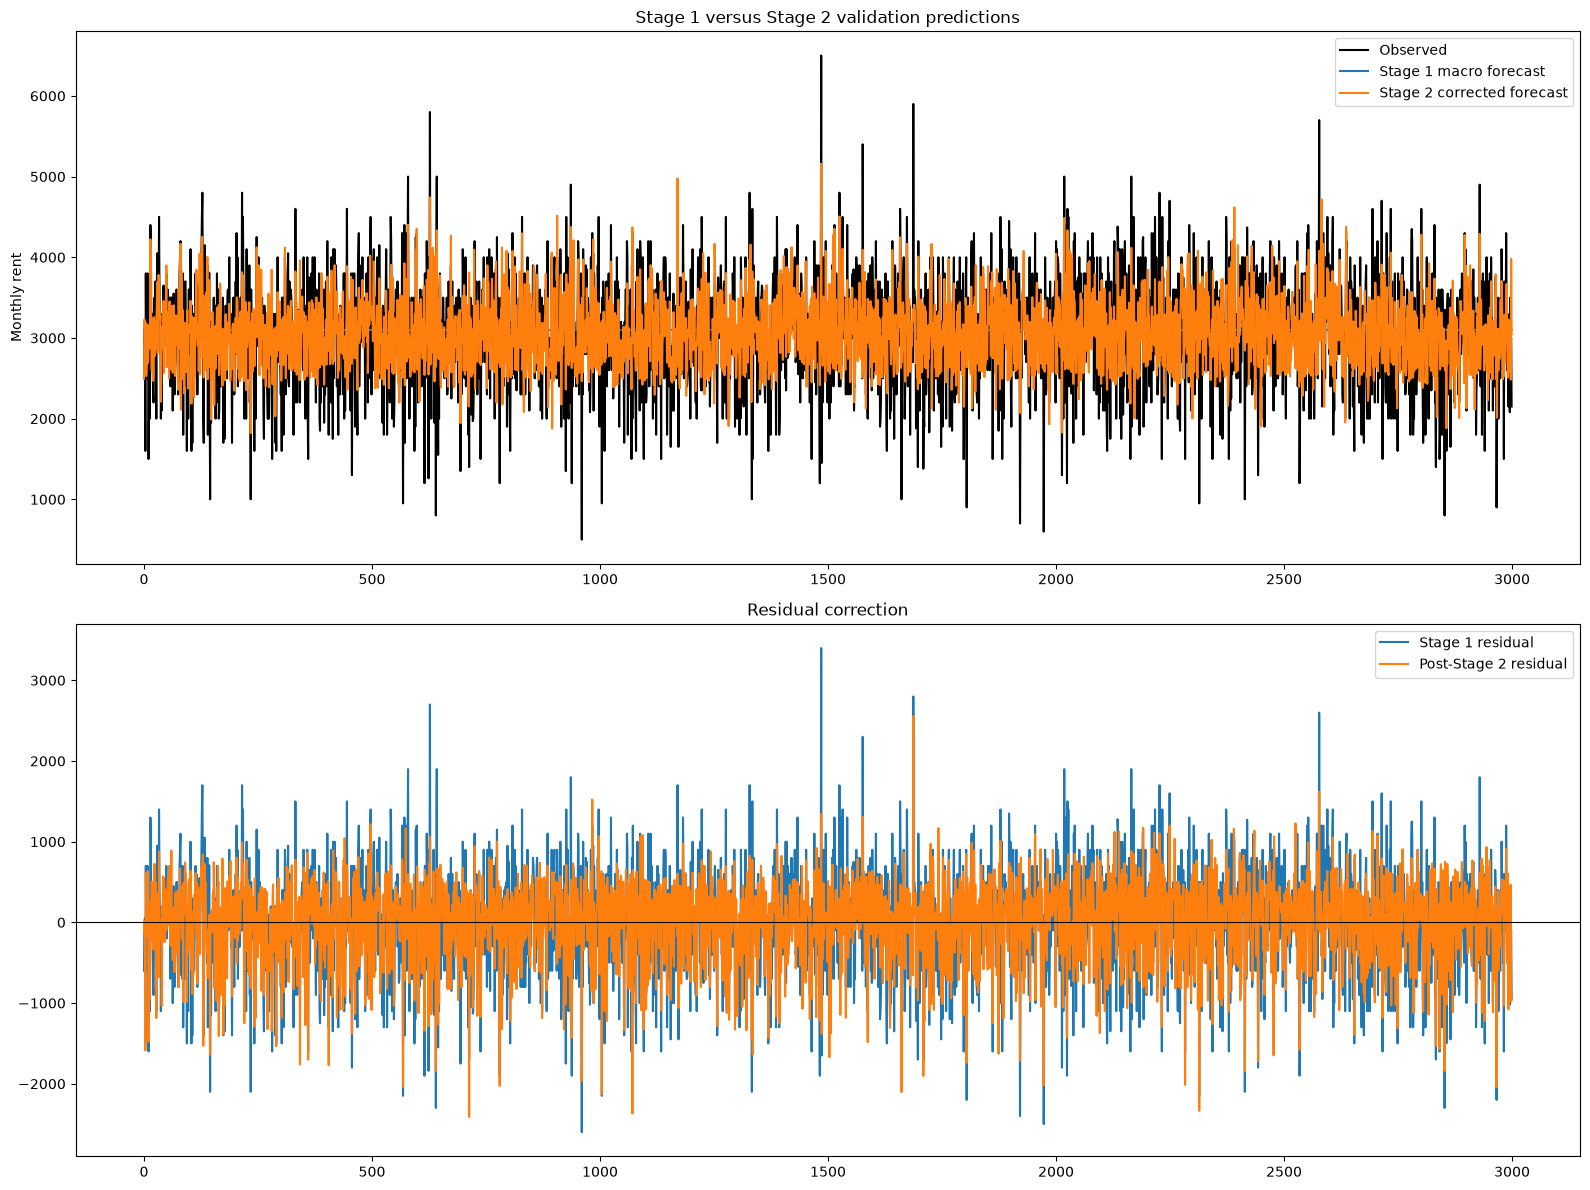

,feature,importance
82,FLAT_TYPE_3-room,0.238940
95,REGION_central region,0.137491
48,PA_PCT_AGE_15_64,0.099559
55,PA_AVG_HOUSEHOLD_SIZE,0.080217
81,FLAT_TYPE_2-room,0.049718
1,FLOOR_AREA_SQM,0.040833
66,ADDRESS_PRIOR_MEDIAN,0.030951
11,LATITUDE,0.029636
59,PA_PCT_OWNER_OCCUPIED,0.028169
3,RENT_YEAR,0.026358


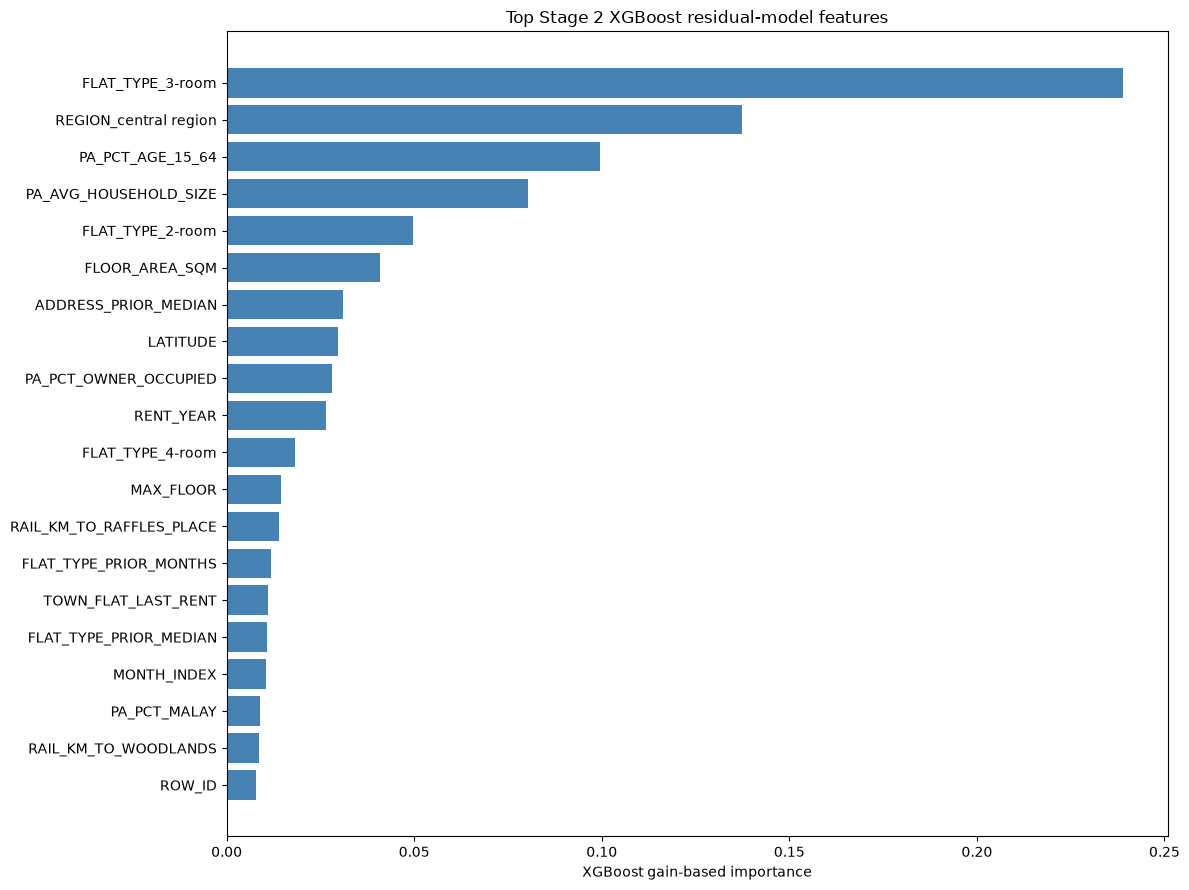

In [53]:
plot_n = min(len(valid_actual), 3000)
fig, axes = plt.subplots(2, 1, figsize=(16, 12))
axes[0].plot(valid_actual[:plot_n], color='black', label='Observed')
axes[0].plot(valid_base[:plot_n], label='Stage 1 macro forecast')
axes[0].plot(valid_corrected[:plot_n], label='Stage 2 corrected forecast')
axes[0].set_title('Stage 1 versus Stage 2 validation predictions'); axes[0].set_ylabel('Monthly rent'); axes[0].legend()
axes[1].plot(valid_actual[:plot_n] - valid_base[:plot_n], label='Stage 1 residual')
axes[1].plot(valid_actual[:plot_n] - valid_corrected[:plot_n], label='Post-Stage 2 residual')
axes[1].axhline(0, color='black', linewidth=.8); axes[1].set_title('Residual correction'); axes[1].legend()
plt.tight_layout(); plt.show()

importance = pd.DataFrame({'feature': selected_features, 'importance': residual_model.feature_importances_}).sort_values('importance', ascending=False)
display(importance.head(25))
top = importance.head(20).sort_values('importance')
plt.figure(figsize=(12, 9)); plt.barh(top['feature'], top['importance'], color='steelblue')
plt.title('Top Stage 2 XGBoost residual-model features'); plt.xlabel('XGBoost gain-based importance')
plt.tight_layout(); plt.show()


## Export train and validation predictions for the better model

In [24]:
# Export observed predictions for both fitted two-stage pipelines.
fit_stage1 = property_df.loc[fit_mask, 'stage1_forecast'].to_numpy(dtype=float)
fit_actual = property_df.loc[fit_mask, TARGET].to_numpy(dtype=float)
fit_holt_stage2 = fit_stage1 + residual_model.predict(X_fit_selected)
fit_rf_stage1 = property_df.loc[fit_mask, 'stage1_rf_forecast'].to_numpy(dtype=float)
fit_rf_stage2 = fit_rf_stage1 + rf_residual_model.predict(X_fit_rf)
valid_rf_stage1 = property_df.loc[valid_mask, 'stage1_rf_forecast'].to_numpy(dtype=float)
valid_rf_stage2 = valid_rf_stage1 + rf_residual_model.predict(X_valid_rf)
fit_output = pd.DataFrame({'ROW_ID': property_df.loc[fit_mask, 'ROW_ID'].to_numpy(), 'MONTH': property_df.loc[fit_mask, 'MONTH'].to_numpy(), 'split': 'train', 'actual_MONTHLY_RENT': fit_actual, 'holt_stage1_prediction': fit_stage1, 'holt_xgb_stage2_prediction': fit_holt_stage2, 'rf_stage1_prediction': fit_rf_stage1, 'rf_xgb_stage2_prediction': fit_rf_stage2})
valid_output = pd.DataFrame({'ROW_ID': property_df.loc[valid_mask, 'ROW_ID'].to_numpy(), 'MONTH': property_df.loc[valid_mask, 'MONTH'].to_numpy(), 'split': 'validation', 'actual_MONTHLY_RENT': property_df.loc[valid_mask, TARGET].to_numpy(dtype=float), 'holt_stage1_prediction': valid_base, 'holt_xgb_stage2_prediction': valid_corrected, 'rf_stage1_prediction': valid_rf_stage1, 'rf_xgb_stage2_prediction': valid_rf_stage2})
train_validation_predictions = pd.concat([fit_output, valid_output], ignore_index=True).sort_values(['split', 'MONTH', 'ROW_ID']).reset_index(drop=True)
train_validation_predictions_path = cfg.TIME_SERIES_OUTPUT_DIR / 'train_validation_predictions_time_series_plus_residual.csv'
train_validation_predictions.to_csv(train_validation_predictions_path, index=False)
print(f'Wrote {len(train_validation_predictions):,} train/validation predictions to {train_validation_predictions_path}')
display(train_validation_predictions.head())


Wrote 112,381 train/validation predictions to /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/train_validation_predictions_time_series_plus_residual.csv


,ROW_ID,MONTH,split,actual_MONTHLY_RENT,holt_stage1_prediction,holt_xgb_stage2_prediction,rf_stage1_prediction,rf_xgb_stage2_prediction
0,37619,2022-01-01,train,2200.0,2248.762016,2184.633515,2315.513845,2286.775615
1,37620,2022-01-01,train,1750.0,2248.762016,2288.444382,2315.513845,2262.424138
2,37621,2022-01-01,train,2000.0,2248.762016,2287.008465,2315.513845,2301.633416
3,37622,2022-01-01,train,2000.0,2248.762016,2338.790543,2315.513845,2424.682485
4,37623,2022-01-01,train,2150.0,2248.762016,2333.869911,2315.513845,2336.925162


In [23]:
# Select the better final two-stage pipeline by validation RMSE.
best_pipeline = pipeline_comparison['RMSE'].idxmin()
best_prediction_col = ('rf_xgb_stage2_prediction' if best_pipeline.startswith('Random Forest') else 'holt_xgb_stage2_prediction')
print('Selected export model:', best_pipeline)
print('Validation RMSE:', pipeline_comparison.loc[best_pipeline, 'RMSE'])
train_export = fit_output[['ROW_ID','MONTH','actual_MONTHLY_RENT',best_prediction_col]].rename(columns={best_prediction_col:'prediction'}).copy()
valid_export = valid_output[['ROW_ID','MONTH','actual_MONTHLY_RENT',best_prediction_col]].rename(columns={best_prediction_col:'prediction'}).copy()
for split_name, split_output in [('train', train_export), ('validation', valid_export)]:
    split_path = cfg.TIME_SERIES_OUTPUT_DIR / f'time_series_plus_residual_best_model_{split_name}_predictions.csv'
    split_output.sort_values(['MONTH','ROW_ID']).to_csv(split_path, index=False)
    print(f'{split_name.capitalize()} predictions: {len(split_output):,} rows -> {split_path}')

Selected export model: Holt Stage 1 → XGBoost Stage 2 validation
Validation RMSE: 434.6687472240572
Train predictions: 77,223 rows -> /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/time_series_plus_residual_best_model_train_predictions.csv
Validation predictions: 35,158 rows -> /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/time_series_plus_residual_best_model_validation_predictions.csv


## 7. Write the competition submission

The competition submission must contain the original test-row identifier and one finite prediction per test row, in original test order.

In [21]:
# Competition submission using the 50,000 rows in test_features.parquet.
competition_test = pd.read_parquet(TEST_PARQUET, engine='pyarrow').copy()
competition_test = competition_test.sort_values('ROW_ID').reset_index(drop=True)
competition_test[property_date] = pd.to_datetime(competition_test[property_date])
competition_test['MONTH'] = competition_test[property_date].dt.to_period('M').dt.to_timestamp()
competition_test['stage1_forecast'] = competition_test['MONTH'].map(stage1_monthly.set_index('MONTH')['stage1_forecast'])
missing = competition_test['stage1_forecast'].isna()
if missing.any():
    full_holt = ExponentialSmoothing(monthly_rent['mean_monthly_rent'].to_numpy(dtype=float), trend='add', damped_trend=True, initialization_method='estimated').fit(optimized=True)
    last_month = monthly_rent['MONTH'].max(); future_months = sorted(competition_test.loc[missing, 'MONTH'].unique())
    horizon = max(1, (max(future_months).year-last_month.year)*12 + max(future_months).month-last_month.month)
    future_forecast = pd.Series(full_holt.forecast(horizon), index=pd.date_range(last_month + pd.offsets.MonthBegin(1), periods=horizon, freq='MS'))
    competition_test.loc[missing, 'stage1_forecast'] = competition_test.loc[missing, 'MONTH'].map(future_forecast)
competition_test['stage1_forecast'] = competition_test['stage1_forecast'].fillna(monthly_rent['mean_monthly_rent'].iloc[-1])
competition_test['stage1_rf_forecast'] = competition_test['MONTH'].map(stage1_monthly.set_index('MONTH')['stage1_rf_forecast'])
missing_rf = competition_test['stage1_rf_forecast'].isna()
if missing_rf.any() and set(feature_cols).issubset(competition_test.columns): competition_test.loc[missing_rf, 'stage1_rf_forecast'] = forest.predict(competition_test.loc[missing_rf, feature_cols])
competition_test['stage1_rf_forecast'] = competition_test['stage1_rf_forecast'].fillna(stage1_monthly['stage1_rf_forecast'].dropna().iloc[-1])
# Compare the two final residual pipelines and submit only the better one.
missing_stage2_cols = [c for c in stage2_feature_cols if c not in competition_test.columns]
competition_test[missing_stage2_cols] = -999
competition_features = pd.get_dummies(competition_test[stage2_feature_cols], dummy_na=True).reindex(columns=X.columns, fill_value=0).replace([np.inf,-np.inf], np.nan).fillna(-999)
holt_prediction = competition_test['stage1_forecast'].to_numpy() + residual_model.predict(selector.transform(competition_features))
rf_prediction = competition_test['stage1_rf_forecast'].to_numpy() + rf_residual_model.predict(selector_rf.transform(competition_features))
best_two_stage = pipeline_comparison['RMSE'].idxmin()
best_prediction = rf_prediction if best_two_stage.startswith('Random Forest') else holt_prediction
submission = pd.DataFrame({'Id': competition_test['ROW_ID'].astype(int), 'Predicted': best_prediction.astype(float)})
assert len(submission) == 50_000 and submission['Id'].equals(pd.Series(np.arange(50_000), name='Id'))
assert np.isfinite(submission['Predicted']).all()
submission_path = cfg.TIME_SERIES_OUTPUT_DIR / 'submission_time_series_plus_residual_best_model.csv'; submission.to_csv(submission_path, index=False)
print(f'Selected final model: {best_two_stage}')
print(f'Wrote best-model submission: {submission_path}')
display(submission.head())

Selected final model: Holt Stage 1 → XGBoost Stage 2 validation
Wrote best-model submission: /Users/marklim/Masters/CS5228/CS5228-project-final/final_report/data/submission_time_series_plus_residual_best_model.csv


,Id,Predicted
0,0,3008.202519
1,1,3464.846867
2,2,3161.822243
3,3,3243.587563
4,4,3437.093297


In [22]:
len(submission)

50000